# California Senate Bill 277: Vaccination Coverage, Exemptions and Measles (2010–2019)

**Research questions**

1. How did kindergarten MMR vaccination coverage and personal-belief exemptions change around the implementation of SB 277?
2. What associations are observed between MMR coverage, vaccination exemptions and reported measles incidence?
3. What do one-year lagged associations and potential confounding factors suggest about these relationships?

**Setting:** California (58 counties), 2010–2019.

**Study type:** Ecological observational analysis of vaccination coverage, exemptions and measles incidence surrounding SB 277.

In [ ]:
# Install only missing analysis packages into the current Jupyter Python environment.
import importlib.util, subprocess, sys
REQUIRED = {'pandas':'pandas', 'numpy':'numpy', 'requests':'requests',
            'matplotlib':'matplotlib', 'seaborn':'seaborn', 'scipy':'scipy',
            'statsmodels':'statsmodels', 'plotly':'plotly'}
missing=[pkg for module,pkg in REQUIRED.items() if importlib.util.find_spec(module) is None]
if missing:
    print('Installing missing packages:', ', '.join(missing))
    subprocess.check_call([sys.executable,'-m','pip','install','--quiet',*missing])

from pathlib import Path
import re, io, warnings, json
import pandas as pd, numpy as np, requests
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import pearsonr, spearmanr
from IPython.display import display, Markdown, HTML
import statsmodels.api as sm
import statsmodels.formula.api as smf

sns.set_theme(style='whitegrid')
pd.set_option('display.max_columns',40)
ROOT=Path.cwd()
DATA=ROOT/'data'
DATA.mkdir(exist_ok=True)
START_YEAR,END_YEAR=2010,2019
COLUMN_OVERRIDES={'vaccine':{},'cases':{},'population':{}}
print('Python:',sys.version.split()[0], '| Data cache:',DATA.resolve())

SOURCES = {
    'kindergarten_2013_2015.csv': 'https://data.chhs.ca.gov/dataset/bc38e725-9180-49e7-97e5-e16cb413a40c/resource/b17f85b5-0cb3-4e33-971d-e9029203c08e/download/school-immunizations-in-kindergarten-by-academic-year-2013-2014-to-2015-16.csv',
    'kindergarten_2016_2018.csv': 'https://data.chhs.ca.gov/dataset/bc38e725-9180-49e7-97e5-e16cb413a40c/resource/4319a7e8-5c63-460c-b412-c7474fd7da2a/download/iz_kindergarten2016-17_to_2018-19_school_year.csv',
    'kindergarten_2019.csv': 'https://data.chhs.ca.gov/dataset/bc38e725-9180-49e7-97e5-e16cb413a40c/resource/a269c0af-3fa7-4b27-8f5b-0bb0dcedfdd2/download/kindergarten_immunizations_academic_year_2019-20-to-2022-23.csv',
    'measles_county.csv': 'https://data.chhs.ca.gov/dataset/bd6a1ca8-dd41-4cbf-84a2-0e899af64b67/resource/a7a4d868-f6d2-49c9-8a11-904c69a0e3a0/download/izb-cases-by-county-year-2024.csv',
    'census_population_2010_2019.csv': 'https://www2.census.gov/programs-surveys/popest/datasets/2010-2019/counties/totals/co-est2019-alldata.csv',
}

def download_cached(filename, url):
    dest = DATA / filename
    old = ROOT / filename
    if not dest.exists() and old.exists() and old.stat().st_size > 100:
        return old
    if dest.exists() and dest.stat().st_size > 100:
        print('CACHED', filename, f'({dest.stat().st_size:,} bytes)')
        return dest
    try:
        response = requests.get(url, headers={'User-Agent':'Mozilla/5.0 (compatible; academic research)'}, timeout=75)
        response.raise_for_status()
        if response.content[:100].lower().startswith((b'<!doctype html', b'<html')):
            raise ValueError('The response contained an HTML page, not CSV data.')
        if len(response.content) < 100 or b',' not in response.content[:1000]:
            raise ValueError('The source did not return a valid-looking CSV.')
        dest.write_bytes(response.content)
        print('DOWNLOADED', filename, f'({len(response.content):,} bytes)')
        return dest
    except Exception as exc:
        print('UNAVAILABLE', filename, '-', str(exc)[:160])
        return None

paths = {name: download_cached(name,url) for name,url in SOURCES.items()}
failed = [name for name, p in paths.items() if p is None]
if failed:
    display(Markdown('**Source files unavailable:** Download and save the following official CSVs in the automatically created `data/` folder: ' + ', '.join('`'+f+'`' for f in failed) + '. Then rerun this cell.'))
    raise FileNotFoundError('Download the listed official CSV inputs into data/ and rerun. No synthetic observations are used.')

def load_csv(path):
    try:
        return pd.read_csv(path, low_memory=False)
    except UnicodeDecodeError:
        return pd.read_csv(path, low_memory=False, encoding='latin1')
raw = {name:load_csv(p) for name,p in paths.items()}
for name, df in raw.items():
    print('\n', name, '→', df.shape)
    print('COLUMNS:', ', '.join(df.columns.astype(str)))
    display(df.head(2))

In [ ]:
# Standardize both CDPH layouts:
#   (1) WIDE: one row per school / county with separate MMR, PBE, PME columns;
#   (2) LONG: multiple school rows, with the vaccine/exemption in a Category column.
# Source: https://data.ca.gov/@california-department-of-public-health/school-immunizations-in-kindergarten-by-academic-year

SKIP_LOCATIONS = {'', 'california', 'statewide', 'state total', 'total',
                  'unknown', 'out of state', 'other', 'all counties'}

def key(s):
    return re.sub(r'[^a-z0-9]+', '', str(s).lower())

def county_name(x):
    if pd.isna(x): return None
    x = re.sub(r'\s+county(?:,\s*ca)?$', '', str(x).strip(), flags=re.I)
    x = re.sub(r'\s+', ' ', x).strip()
    return None if key(x) in {key(v) for v in SKIP_LOCATIONS} else x.title()

def pick(df, choices, kind='vaccine', field='', required=False):
    overrides = COLUMN_OVERRIDES.get(kind, {})
    if field in overrides:
        target=overrides[field]
        if target not in df.columns:
            raise ValueError(f'{kind}.{field} override {target!r} not found in {list(df.columns)}')
        return target
    normalized={key(c):c for c in df.columns}
    for option in choices:
        if key(option) in normalized:
            return normalized[key(option)]
    if required:
        raise ValueError(f'Unable to identify {kind}.{field}. Columns: {list(df.columns)}')
    return None

def numbers(values):
    # Respect data suppression: * and <5 are missing, not zeros.
    return pd.to_numeric(values.astype('string').str.replace(',', '', regex=False)
                       .str.replace('%', '', regex=False).str.strip(), errors='coerce')

def year_values(values):
    return pd.to_numeric(values.astype('string').str.extract(r'((?:19|20)\d{2})',expand=False),
                         errors='coerce').astype('Int64')

def to_percentage(values, title):
    x=numbers(values)
    if x.notna().any() and x.dropna().max()<=1.000001 and re.search(r'(percent|pct|rate|prop|coverage)',key(title)):
        x=x*100
    return x.where(x.between(0,100))

METRICS=('mmr_pct','pbe_pct','medical_pct')
VAX_ALIASES={
 'year':['School Year','Academic Year','SchoolYear','Year','school_year'],
 'county':['County','County Name','county_name'],
 'school':['School Code','SchoolCode','CDS Code','School ID','School Number','School Name','SchoolName'],
 'students':['Enrollment','Kindergarten Enrollment','Number of Students','Total Students','Students','Kindergarten Students','Total Enrollment'],
 'reported':['Reported','Reporting Status'],
 'category':['Category','Row Label','Vaccine Category','Immunization Category','Immunization','Metric'],
 'long_count':['Count','Number','Number of Students in Category','Students in Category','Numerator','Category Count','Total Count'],
 'long_percent':['Percent','Percentage','Pct','Rate','Proportion','Category Percent'],
 'mmr_pct':['MMR Percent','MMR Percentage','MMR Pct','MMR Coverage','MMR Coverage Rate','Percent MMR','MMR_2_PCT','MMR_PCT','percent_mmr','2+ MMR Percent'],
 'mmr_count':['MMR Count','Number MMR','MMR 2 Doses','2+ MMR','2+MMR','2 MMR','MMR 2','MMR Vaccinated'],
 'pbe_pct':['PBE Percent','PBE Pct','PBE Rate','Percent PBE','Personal Beliefs Exemption Percent','Personal Beliefs Exemptions Percent','PBE_PCT'],
 'pbe_count':['PBE Count','Personal Beliefs Exemption','Personal Beliefs Exemptions','Number PBE'],
 'medical_pct':['PME Percent','PME Pct','Medical Exemptions Percent','Medical Exemption Rate','Medical Exemption Percent','PME_PCT'],
 'medical_count':['PME Count','Permanent Medical Exemption','Medical Exemption Count','Medical Exemptions'],
}

def category_metric(label):
    """Only primary categories; do not sum PBE subcategories or 1-dose MMR."""
    s=key(label)
    if s in {'2mmr','2plusmmr','mmr2doses','mmr2dose','mmr2','2dosesmmr','2ormoremmr','2measlesmumpsrubella'}:
        return 'mmr_pct'
    if s in {'pbe','personalbeliefexemption','personalbeliefsexemption',
             'personalbeliefexemptions','personalbeliefsexemptions','totalpbe','totalpersonalbeliefsexemptions',
             'personalbeliefexemptionpbe','personalbeliefsexemptionpbe',
             'personalbeliefexemptionspbe','personalbeliefsexemptionspbe'}:
        return 'pbe_pct'
    if s in {'pme','permanentmedicalexemption','permanentmedicalexemptions',
             'medicalexemption','medicalexemptions','totalmedicalexemptions',
             'permanentmedicalexemptionpme','permanentmedicalexemptionspme',
             'medicalexemptionpme','medicalexemptionspme'}:
        return 'medical_pct'
    return None

def empty_vax():
    return pd.DataFrame(columns=['county','year','students','mmr_pct','pbe_pct','medical_pct',
                                 'mmr_students','pbe_students','medical_students','source_file'])

def parse_kindergarten(df, source_name):
    raw=df.copy()
    yc=pick(raw,VAX_ALIASES['year'],field='year',required=True)
    cc=pick(raw,VAX_ALIASES['county'],field='county',required=True)
    ec=pick(raw,VAX_ALIASES['students'],field='students')
    sc=pick(raw,VAX_ALIASES['school'],field='school')
    rc=pick(raw,VAX_ALIASES['reported'],field='reported')
    cat=pick(raw,VAX_ALIASES['category'],field='category')
    raw['year']=year_values(raw[yc]); raw['county']=raw[cc].map(county_name)
    raw=raw[raw.year.between(START_YEAR,END_YEAR) & raw.county.notna()].copy()
    if raw.empty:
        print('NOTE',source_name,': no rows in 2010-2019.'); return empty_vax()
    if rc:
        valid=raw[rc].astype(str).str.strip().str.lower().isin(['y','yes','true','1','reported'])
        print(f'{source_name}: excluding {int((~valid).sum()):,} non-reporting rows.')
        raw=raw[valid].copy()
    if raw.empty: return empty_vax()
    raw['_enrollment']=numbers(raw[ec]) if ec else np.nan
    raw.loc[~raw['_enrollment'].gt(0),'_enrollment']=np.nan
    # A stable school identifier is required to prevent repeated enrollment counting.
    if sc:
        raw['_school']=raw[sc].astype('string').str.strip()
    elif cat is not None:
        # Cannot establish unique schools from long observations without school IDs.
        raise ValueError(f'{source_name}: long-format file has no school identifier. Columns: {list(df.columns)}')
    else:
        raw['_school']=np.arange(len(raw)).astype(str)

    result=[]
    if cat is not None:
        # CDPH's 2013-15 file stores labels such as "2+ MMR" as rows in Category.
        raw['_metric']=raw[cat].map(category_metric)
        recognized=raw.loc[raw._metric.notna(),cat].dropna().value_counts().head(18)
        print(f'{source_name}: long-format categories selected: {recognized.to_dict()}')
        unrecognized=raw.loc[raw._metric.isna() & raw[cat].astype(str).str.contains(r'mmr|belief|medical|\bpbe\b|\bpme\b',case=False,regex=True),cat].dropna().unique()
        if len(unrecognized): print('Other vaccine/exemption categories (excluded):',list(unrecognized[:20]))
        count_col=pick(raw,VAX_ALIASES['long_count'],field='long_count')
        rate_col=pick(raw,VAX_ALIASES['long_percent'],field='long_percent')
        if not count_col and not rate_col:
            print(f'WARNING {source_name}: Category found but neither a count nor a percentage column was identified.')
            print('Available source fields:',list(df.columns))
            print('If the only candidate is VALUE, validate the CDPH data dictionary before renaming it to Number (count) or Percent (rate).')
            return empty_vax()
        relevant=raw[raw._metric.notna()].copy()
        if count_col:
            relevant['_num']=numbers(relevant[count_col])
            relevant['_num']=relevant['_num'].where(relevant['_num'].ge(0))
            relevant.loc[relevant['_num']>relevant['_enrollment'],'_num']=np.nan
        else:
            relevant['_num']=np.nan
        if rate_col:
            relevant['_rate']=to_percentage(relevant[rate_col],rate_col)
        else:
            relevant['_rate']=np.nan
        # If only a rate was supplied, derive equivalent numerator for weighted pooling.
        use_rate=relevant['_num'].isna() & relevant['_rate'].notna() & relevant._enrollment.gt(0)
        relevant.loc[use_rate,'_num']=relevant.loc[use_rate,'_rate']*relevant.loc[use_rate,'_enrollment']/100
        raw_sch=raw.groupby(['county','year','_school'],dropna=False)['_enrollment'].max()
        relevant=relevant.dropna(subset=['_num','_enrollment'])
        # Never sum repeated category rows from the same school: dedupe identical records.
        relevant=relevant.drop_duplicates(['county','year','_school','_metric','_num'])
        conflict=relevant.duplicated(['county','year','_school','_metric'],keep=False)
        if conflict.any():
            print(f'WARNING {source_name}: conflicting duplicated school/category records; excluded',int(conflict.sum()),'rows.')
            relevant=relevant[~conflict].copy()
        long_summary=relevant.groupby(['county','year','_metric'],observed=True).agg(
            valid_numerator=('_num','sum'), valid_denominator=('_enrollment','sum')).reset_index()
        for (county,year), enrollments in raw_sch.groupby(level=[0,1]):
            entry={'county':county,'year':int(year),'students':enrollments.sum(min_count=1)}
            for m in METRICS:
                sub=long_summary[(long_summary.county==county)&(long_summary.year==year)&(long_summary._metric==m)]
                entry[m]=100*sub.valid_numerator.iloc[0]/sub.valid_denominator.iloc[0] if len(sub) and sub.valid_denominator.iloc[0]>0 else np.nan
                entry[m.replace('_pct','_students')]=sub.valid_denominator.iloc[0] if len(sub) else np.nan
            result.append(entry)
    else:
        # One metric per column: convert percentages or counts, weight by observed enrollment.
        for metric in METRICS:
            pct=pick(raw,VAX_ALIASES[metric],field=metric)
            ct=pick(raw,VAX_ALIASES[metric.replace('_pct','_count')],field=metric.replace('_pct','_count'))
            if pct:
                raw[metric]=to_percentage(raw[pct],pct)
            elif ct and ec:
                raw[metric]=(100*numbers(raw[ct])/raw['_enrollment']).where(lambda x:x.between(0,100))
            else:
                raw[metric]=np.nan
                print(f'NOTE {source_name}: {metric} is unavailable in wide columns.')
        wide=raw.drop_duplicates(['county','year','_school']+list(METRICS))
        conflicts=wide.duplicated(['county','year','_school'],keep=False)
        if conflicts.any():
            print(f'WARNING {source_name}: conflicting duplicated schools; excluding',int(conflicts.sum()),'rows.')
            wide=wide[~conflicts].copy()
        for (county,year),g in wide.groupby(['county','year'],dropna=False):
            entry={'county':county,'year':int(year),'students':g._enrollment.sum(min_count=1)}
            for m in METRICS:
                included=g[g[m].notna() & g._enrollment.gt(0)]
                entry[m]=np.average(included[m],weights=included._enrollment) if len(included) else np.nan
                entry[m.replace('_pct','_students')]=included._enrollment.sum(min_count=1)
            result.append(entry)
    final=pd.DataFrame(result) if result else empty_vax()
    if not final.empty:
        for m in METRICS:
            final[m]=final[m].where(final[m].between(0,100))
        print(f'{source_name}: {len(final)} county-years; MMR {final.mmr_pct.notna().sum()}, PBE {final.pbe_pct.notna().sum()}, medical {final.medical_pct.notna().sum()}')
        if not final.mmr_pct.notna().any():
            print(f'WARNING: {source_name} has no validated 2-dose MMR observations. They remain missing; inspect source labels.')
    final['source_file']=source_name
    return final

vax_parts=[parse_kindergarten(raw[name],name) for name in SOURCES if name.startswith('kindergarten_')]
optional_early=DATA/'early_kindergarten_2010_2012.csv'
if optional_early.exists():
    early=load_csv(optional_early)
    required={'county','year','mmr_pct','pbe_pct'}
    if not required.issubset(early.columns):
        raise ValueError(f'Historical archive requires columns: {sorted(required)}')
    early['county']=early.county.map(county_name)
    early['year']=pd.to_numeric(early.year,errors='coerce')
    early=early[early.year.between(2010,2012)&early.county.notna()].copy()
    for c in ['students','medical_pct','mmr_students','pbe_students','medical_students']:
        if c not in early.columns: early[c]=np.nan
    for m in METRICS:
        early[m]=pd.to_numeric(early[m],errors='coerce').where(lambda s:s.between(0,100))
    early['source_file']='historical_archive_verified'
    vax_parts.append(early[empty_vax().columns])
vax=pd.concat(vax_parts,ignore_index=True)
if not vax.empty and vax.duplicated(['county','year']).any():
    raise ValueError('Multiple vaccine sources overlap in the same county-year; verify year coding.')
print('Valid vaccine county-years:',len(vax))
print('Observed MMR years:',sorted(vax.loc[vax.mmr_pct.notna(),'year'].unique().tolist()) if len(vax) else [])
display(vax.head())

In [ ]:
CASE_ALIASES={
 'county':['County','County Name','county_name'],
 'year':['Year','Report Year','year_of_onset','Onset Year'],
 'disease':['Disease','Disease Name','Condition','Disease_Name'],
 'cases':['Cases','Case Count','Case_Count','Count','Number of Cases','Total Cases'],
}

def parse_cases(df):
    d=df.copy()
    cc=pick(d,CASE_ALIASES['county'],'cases','county',True)
    yc=pick(d,CASE_ALIASES['year'],'cases','year',True)
    dc=pick(d,CASE_ALIASES['disease'],'cases','disease',True)
    nc=pick(d,CASE_ALIASES['cases'],'cases','cases',True)
    # Exact disease match prevents counting measles subtypes more than once.
    d=d[d[dc].astype(str).str.strip().str.lower().eq('measles')].copy()
    sexcol=pick(d,['Sex','Gender'],'cases','sex')
    if sexcol and d[sexcol].astype(str).str.lower().eq('total').any():
        d=d[d[sexcol].astype(str).str.lower().eq('total')].copy()
    d['county']=d[cc].map(county_name)
    d['year']=year_values(d[yc]); d['measles_cases']=numbers(d[nc])
    d=d[d.year.between(START_YEAR,END_YEAR) & d.county.notna()].copy()
    neg=d.measles_cases.dropna().lt(0).any()
    if neg: raise ValueError('Negative case counts detected.')
    # Different types of measles must not be double-counted.
    dup=d.duplicated(['county','year'],keep=False)
    if dup.any():
        display(d.loc[dup, [cc,yc,dc,nc]].head(20))
        raise ValueError('Multiple measles rows per county-year detected; inspect whether categories overlap before aggregating.')
    return d[['county','year','measles_cases']]

def parse_population(df):
    d=df.copy()
    sc=pick(d,['STATE'],'population','state',True)
    cc=pick(d,['COUNTY'],'population','county_code',True)
    name=pick(d,['CTYNAME'],'population','county_name',True)
    d=d[pd.to_numeric(d[sc],errors='coerce').eq(6) & pd.to_numeric(d[cc],errors='coerce').gt(0)].copy()
    d['county']=d[name].map(county_name)
    d['fips']=d[sc].astype(int).astype(str).str.zfill(2)+d[cc].astype(int).astype(str).str.zfill(3)
    columns=[f'POPESTIMATE{year}' for year in range(START_YEAR,END_YEAR+1)]
    missing=[c for c in columns if c not in d]
    if missing: raise ValueError('Census population columns missing: '+str(missing))
    d=d.melt(id_vars=['county','fips'],value_vars=columns,var_name='year',value_name='population')
    d['year']=d.year.str.extract(r'(\d{4})').astype(int)
    d['population']=pd.to_numeric(d.population,errors='coerce')
    return d[['county','fips','year','population']]

cases=parse_cases(raw['measles_county.csv'])
pop=parse_population(raw['census_population_2010_2019.csv'])
print('Measles rows:',len(cases),'years:',sorted(cases.year.unique().tolist()))
print('Census county-years:',len(pop))
display(cases.head()); display(pop.head())

panel = (pop.merge(vax,on=['county','year'],how='left',validate='one_to_one')
            .merge(cases,on=['county','year'],how='left',validate='one_to_one'))
panel['measles_per_100k']=100_000*panel.measles_cases/panel.population
panel['post_2016']=(panel.year>=2016).astype(int)
panel['policy_period']=np.select([panel.year<2015,panel.year==2015,panel.year>=2016],['Pre-enactment','Enactment / transition','Post-implementation'],default='Other')
panel['mmr_lag1']=panel.groupby('county').mmr_pct.shift(1)
panel['pbe_lag1']=panel.groupby('county').pbe_pct.shift(1)
panel['medical_lag1']=panel.groupby('county').medical_pct.shift(1)

# Optional audited county-year covariates. These are not 'adjusted for' unless supplied and included in a model.
cov_file=DATA/'county_covariates.csv'
allowed_covariates=['median_household_income','poverty_pct','uninsured_pct','density_per_sq_mile','pct_under_18']
if cov_file.exists():
    cov=load_csv(cov_file)
    if not {'county','year'}.issubset(cov.columns): raise ValueError('Covariate file requires county and year.')
    cov['county']=cov['county'].map(county_name)
    cov['year']=pd.to_numeric(cov['year'],errors='coerce').astype('Int64')
    cov_cols=[c for c in allowed_covariates if c in cov.columns]
    if cov.duplicated(['county','year']).any(): raise ValueError('Duplicate covariate county-years.')
    panel=panel.merge(cov[['county','year']+cov_cols],on=['county','year'],how='left',validate='one_to_one')
else:
    cov_cols=[]

cols=['mmr_pct','pbe_pct','medical_pct','measles_cases','population']
coverage=panel.groupby('year')[cols].agg(lambda s:int(s.notna().sum()))
coverage.columns=[f'counties_with_{v}' for v in coverage.columns]
print('Availability by year (out of 58 CA counties):'); display(coverage)
print('Merged counties:',panel.county.nunique(),'county-years:',len(panel))
print('Matching measles observations:',panel.measles_cases.notna().sum())
assert len(pop)==580 and panel[['county','year']].duplicated().sum()==0, 'Expected full 58 × 10 county-year grid.'
assert panel.population.gt(0).all(), 'Population must be positive.'

## 5 · Statewide trends with policy timing

Rates are weighted by valid kindergarten enrollment, and measles totals are displayed only for calendar years with complete 58-county case coverage. The vertical reference line marks 2016, while 2015 was the enactment and transition year.

Coverage aggregation: Enrollment-weighted among county records with validated metric-specific enrollment; censored schools excluded


,year,mmr_pct,pbe_pct,medical_pct,measles_cases,measles_county_coverage,cases_observed_sum,population,mmr_counties,pbe_counties,measles_per_100k
0,2010,NaN,NaN,NaN,27.0,58,27.0,37319502,0,0,0.072
1,2011,NaN,NaN,NaN,33.0,58,33.0,37638369,0,0,0.088
2,2012,NaN,NaN,NaN,8.0,58,8.0,37948800,0,0,0.021
3,2013,NaN,3.094,0.185,18.0,58,18.0,38260787,0,58,0.047
4,2014,NaN,2.491,0.190,75.0,58,75.0,38596972,0,57,0.194
5,2015,NaN,2.331,0.167,125.0,58,125.0,38918045,0,57,0.321
6,2016,NaN,1.405,1.327,24.0,58,24.0,39167117,0,55,0.061
7,2017,NaN,0.907,1.508,15.0,58,15.0,39358497,0,57,0.038
8,2018,NaN,NaN,1.633,23.0,58,23.0,39461588,0,0,0.058
9,2019,95.763,NaN,1.641,72.0,58,72.0,39512223,57,0,0.182


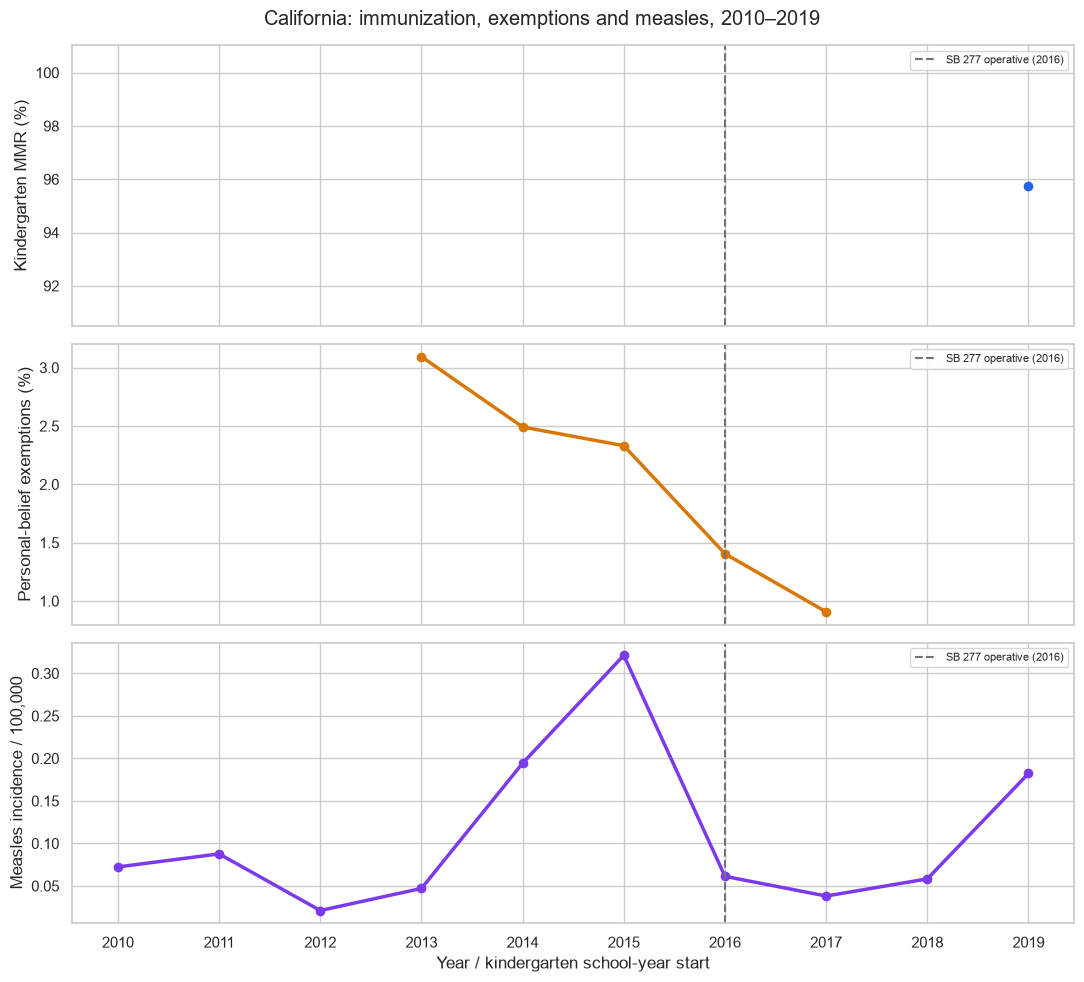

In [4]:
def state_rate(df, col):
    # For county-level rates, use metric-specific student denominator;
    # never imply a statewide estimate from an unweighted mean.
    dencol=col.replace('_pct','_students')
    x=df[df[col].notna() & df[dencol].gt(0)].copy()
    if x.empty: return np.nan
    return np.average(x[col],weights=x[dencol])

rows=[]
for year,g in panel.groupby('year'):
    n_measles=int(g.measles_cases.notna().sum())
    rows.append({'year':year,'mmr_pct':state_rate(g,'mmr_pct'), 'pbe_pct':state_rate(g,'pbe_pct'),
                 'medical_pct':state_rate(g,'medical_pct'),
                 'measles_cases':g.measles_cases.sum() if n_measles==58 else np.nan,
                 'measles_county_coverage':n_measles,
                 'cases_observed_sum':g.measles_cases.sum(min_count=1),
                 'population':g.population.sum(),
                 'mmr_counties':g.mmr_pct.notna().sum(), 'pbe_counties':g.pbe_pct.notna().sum()})
state=pd.DataFrame(rows).sort_values('year')
state['measles_per_100k']=100_000*state.measles_cases/state.population
coverage_label='Enrollment-weighted among county records with validated metric-specific enrollment; censored schools excluded'
print('Coverage aggregation:',coverage_label)
display(state.round(3))

fig,axes=plt.subplots(3,1,figsize=(11,10),sharex=True)
for ax,(col,title,color) in zip(axes,[('mmr_pct','Kindergarten MMR (%)','#2563eb'),('pbe_pct','Personal-belief exemptions (%)','#d97706'),('measles_per_100k','Measles incidence / 100,000','#7c3aed')]):
    ax.plot(state.year,state[col],marker='o',lw=2.5,color=color)
    ax.axvline(2016,ls='--',color='0.45',label='SB 277 operative (2016)')
    ax.set_ylabel(title); ax.legend(loc='best',fontsize=8)
axes[-1].set_xticks(range(2010,2020)); axes[-1].set_xlabel('Year / kindergarten school-year start')
fig.suptitle('California: immunization, exemptions and measles, 2010–2019')
fig.tight_layout()
plt.show()

## 6 · Before–after description

The observed comparison uses school-year starts **2013–2015** versus **2016–2019**, conditional on valid measurements. It is not a causal effect of SB 277. Personal-belief exemptions were legally phased out and their post-2016 values are not a stable measure of underlying vaccine refusal. The 2015–16 year also warrants sensitivity analysis as a transition period.

,measure,pre_mean_2013_2015,post_mean_2016_2019,difference_post_minus_pre,n_pre_years,n_post_years
0,mmr_pct,NaN,95.763,NaN,0,1
1,pbe_pct,2.639,1.156,-1.483,3,2
2,medical_pct,0.181,1.527,1.347,3,4
3,measles_per_100k,0.188,0.085,-0.103,3,4


Interpretation: descriptive comparisons only; the PBE rate is not definitionally stable across the policy.


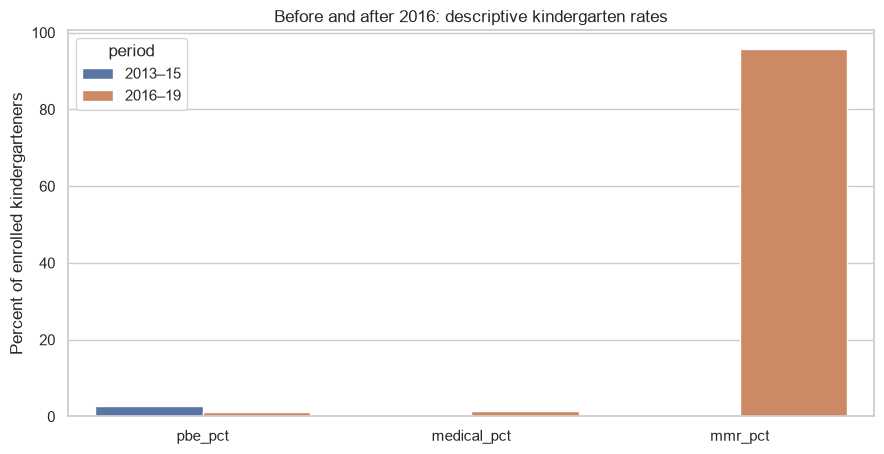

In [5]:
pre=state[state.year.between(2013,2015)]
post=state[state.year.between(2016,2019)]
comparisons=[]
for var in ['mmr_pct','pbe_pct','medical_pct','measles_per_100k']:
    a=pre[var].dropna(); b=post[var].dropna()
    comparisons.append({'measure':var,'pre_mean_2013_2015':a.mean() if len(a) else np.nan,
                        'post_mean_2016_2019':b.mean() if len(b) else np.nan,
                        'difference_post_minus_pre':b.mean()-a.mean() if len(a) and len(b) else np.nan,
                        'n_pre_years':len(a),'n_post_years':len(b)})
change=pd.DataFrame(comparisons)
display(change.round(3)); 
print('Interpretation: descriptive comparisons only; the PBE rate is not definitionally stable across the policy.')
# Compare visually; missing source periods remain absent rather than filled in.
plot_change=change[change.measure.isin(['mmr_pct','pbe_pct','medical_pct'])].copy()
if len(plot_change):
    long=plot_change.melt(id_vars='measure',value_vars=['pre_mean_2013_2015','post_mean_2016_2019'],var_name='period',value_name='rate')
    long['period']=long.period.map({'pre_mean_2013_2015':'2013–15','post_mean_2016_2019':'2016–19'})
    fig,ax=plt.subplots(figsize=(9,4.7))
    sns.barplot(data=long.dropna(subset=['rate']),x='measure',y='rate',hue='period',ax=ax)
    ax.set(title='Before and after 2016: descriptive kindergarten rates',xlabel='',ylabel='Percent of enrolled kindergarteners')
    plt.tight_layout();plt.show()

## 7 · Correlations and one-year lagged associations

Pearson and Spearman coefficients summarize county-year associations. Their conventional p-values do **not** fully account for repeated observations within the same county or geographic clustering and should be treated as exploratory. The personal-belief exemption series is restricted to pre-implementation years for these analyses.

,exposure,n,years,pearson_r,pearson_p,spearman_rho,spearman_p,status
0,mmr_pct,57,2019,-0.0767,0.5708,-0.0800,0.5544,Exploratory pooled county-year association; in...
1,mmr_lag1,0,,NaN,NaN,NaN,NaN,Not estimable: limited non-missing variation
2,pbe_pct,172,"2013,2014,2015",-0.0643,0.4017,-0.1484,0.0521,Exploratory pooled county-year association; in...
3,pbe_lag1,115,"2014,2015",-0.1416,0.1311,-0.1852,0.0475,Exploratory pooled county-year association; in...
4,medical_pct,398,"2013,2014,2015,2016,2017,2018,2019",0.0236,0.6387,0.0001,0.9983,Exploratory pooled county-year association; in...
5,medical_lag1,341,"2014,2015,2016,2017,2018,2019",0.0394,0.4687,0.0375,0.4904,Exploratory pooled county-year association; in...


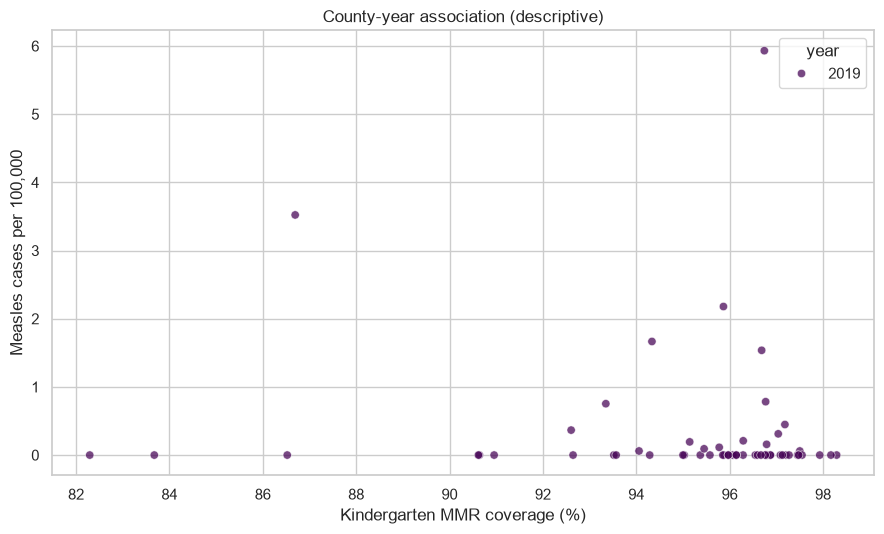

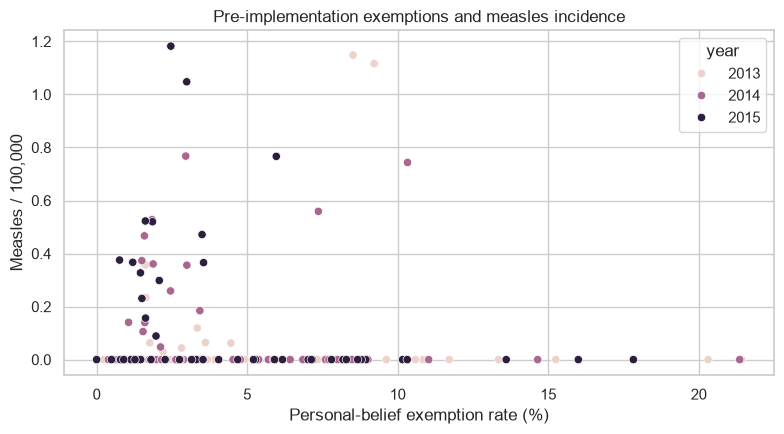

In [6]:
def assoc(df, exposure, outcome='measles_per_100k', years=None, minimum=15):
    d=df.copy()
    if years is not None: d=d[d.year.isin(years)]
    d=d[['county','year',exposure,outcome]].replace([np.inf,-np.inf],np.nan).dropna()
    if len(d)<minimum or d[exposure].nunique()<3 or d[outcome].nunique()<3:
        return {'exposure':exposure,'n':len(d),'years':','.join(map(str,sorted(d.year.unique()))),
                'pearson_r':np.nan,'pearson_p':np.nan,'spearman_rho':np.nan,'spearman_p':np.nan,'status':'Not estimable: limited non-missing variation'}
    p=pearsonr(d[exposure],d[outcome]); s=spearmanr(d[exposure],d[outcome])
    return {'exposure':exposure,'n':len(d),'years':','.join(map(str,sorted(d.year.unique()))),
            'pearson_r':p.statistic,'pearson_p':p.pvalue,'spearman_rho':s.statistic,'spearman_p':s.pvalue,
            'status':'Exploratory pooled county-year association; independence assumption violated'}

correlations=pd.DataFrame([
    assoc(panel,'mmr_pct'),assoc(panel,'mmr_lag1'),
    assoc(panel,'pbe_pct',years=range(2010,2016)),
    assoc(panel,'pbe_lag1',years=range(2011,2016)),
    assoc(panel,'medical_pct'), assoc(panel,'medical_lag1')])
display(correlations.round(4)); 
scatter=panel[['county','year','mmr_pct','measles_per_100k']].dropna()
if len(scatter)>5:
    fig,ax=plt.subplots(figsize=(9,5.5))
    sns.scatterplot(data=scatter,x='mmr_pct',y='measles_per_100k',hue='year',palette='viridis',ax=ax,alpha=.72)
    ax.set(title='County-year association (descriptive)',xlabel='Kindergarten MMR coverage (%)',ylabel='Measles cases per 100,000')
    fig.tight_layout();plt.show()
# Exemptions vs incidence, restricted to the pre-implementation period.
pbe_scatter=panel.loc[panel.year.between(2013,2015),['pbe_pct','measles_per_100k','year']].dropna()
if len(pbe_scatter)>5:
    fig,ax=plt.subplots(figsize=(8,4.5))
    sns.scatterplot(data=pbe_scatter,x='pbe_pct',y='measles_per_100k',hue='year',ax=ax)
    ax.set(xlabel='Personal-belief exemption rate (%)',ylabel='Measles / 100,000',title='Pre-implementation exemptions and measles incidence')
    plt.tight_layout();plt.show()

## 10 · Confounders, alternative explanations and measurement limitations

| Factor | Potential role | Analytical response |
|---|---|---|
| County poverty, income and education | May influence healthcare access, uptake and neighborhood contact patterns | Add validated county-year socioeconomic covariates in a sensitivity model |
| Insurance and healthcare accessibility | May affect vaccination and detection of measles | Describe and adjust only for appropriately timed independent measures |
| Age composition | Total population is not kindergarten vaccination cohort | Sensitivity by population structure; do not interpret kindergarten MMR as all-age immunity |
| Travel/importation and outbreak seeding | Outbreak introductions may vary independently of local vaccination rates | Contextualize notable outbreak years; seek importation data if available |
| Geographic clustering and vaccine hesitancy | County averages can hide susceptible pockets | Discuss ecological fallacy; examine local clustering where data support it |
| AB 2109 and other policy changes | Exemption patterns may change before 2016 | Mark earlier policy interventions; do not equate every later change to SB 277 |
| Medical exemptions and conditional entrants | May be changed by SB 277 itself | Treat as additional outcomes, **not automatically as pre-exposure confounders** |
| Case reporting and ascertainment | Surveillance practices affect recorded incidence | Evaluate completeness; never assume missing case rows are zeros |
| Reverse causation / outbreak response | Publicized measles outbreaks can prompt vaccination campaigns and changes in uptake, obscuring temporal direction | Explore prior-year coverage as a predictor; note that annual/ecological lags cannot exclude feedback |

**Identification limitation:** The analyses shown here are descriptive and unadjusted for most potential confounders. A local `county_covariates.csv`, if supplied, can support subsequent sensitivity analysis, but no multivariable adjustment is claimed in this summary. Medical exemptions and other variables affected by the policy should not automatically be used as adjustment covariates.

**Interpretation:** The data are ecological; no association directly establishes causality or individual vaccine effectiveness. County-level school coverage may not reflect adult immunity, imported exposure, or transmission within small communities. Recorded case counts can be sparse and ascertainment may change over time.

**Reverse causation:** Higher measured incidence may precede increased vaccination demand or intensified surveillance rather than result from lower coverage. The one-year lag helps establish an ordering convention, but it does not eliminate feedback, omitted outbreak exposure, or the calendar-year/school-year alignment problem.


**Sources:** [California Department of Public Health, school immunizations](https://data.ca.gov/@california-department-of-public-health/school-immunizations-in-kindergarten-by-academic-year); [California Department of Public Health, vaccine-preventable disease cases](https://data.ca.gov/@california-department-of-public-health/vaccine-preventable-disease-cases-by-county-and-year); [U.S. Census Bureau, county population estimates](https://www.census.gov/programs-surveys/popest.html).